<a href="https://colab.research.google.com/github/drshahizan/Python-big-data/blob/main/assignment/ass6/bdm/Sambal/BigDataProcessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Assignment 6: Mastering Big Data Handling**

**GROUP NAME: SAMBAL**

**TEAM MEMBERS:**
```
MOHD NOR BIN MOHIDIN (MCS231008)
ZUHAYR ARIF BIN ZAKARIA (MCS231002)
```

##Downloading Kaggle Data set directly into Google Colab

In [ ]:
# Install Kaggle Phyton Library
! pip install kaggle

In [ ]:
# Mount the Google Drive to store Kaggle API Credential
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Make a directory for Kaggle at temporary location on drive
! mkdir ~/.kaggle

In [ ]:
# upload the jason file to google drive and copy to temporary location
!cp /content/drive/MyDrive/kaggle.json ~/.kaggle/kaggle.json

! chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d threnjen/2019-airline-delays-and-cancellations -f full_data_flightdelay.csv

In [ ]:
! unzip full_data_flightdelay.csv.zip

In [ ]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Checking how much memory used if loading full CSV

In [ ]:
# Checking information if loading full CSV

df = pd.read_csv("full_data_flightdelay.csv")
df.info(verbose=False, memory_usage="deep")

##Strategies for Big Dataset

###**1) Load Less Data**

Load only required columns instead all columns

In [ ]:
# Check the columns name
df.columns

In [ ]:
# Only 10 columns needed instead of 26 columns

df = pd.read_csv("full_data_flightdelay.csv", usecols=['MONTH', 'DAY_OF_WEEK', 'DEP_DEL15', 'DEP_TIME_BLK', 'DISTANCE_GROUP','SEGMENT_NUMBER', 'CONCURRENT_FLIGHTS','CARRIER_NAME', 'AIRPORT_FLIGHTS_MONTH', 'AIRLINE_FLIGHTS_MONTH'])

# View Sampel Data for 10 columns
df

Checking memory used after load only 10 columns needed

In [ ]:
df.info(verbose=False, memory_usage="deep")

As a result, load less data which is load only required columns has reduce memory usage from 2.9 GB to 1.3 GB

###**2) Use Chunking**

In [ ]:
# Declare the size of the chunk in the beginning.
# Then using read_csv() with the chunksize parameter, returns an object we can iterate over.

chunk_size=50000
batch_no=1
for chunk in pd.read_csv('full_data_flightdelay.csv',chunksize=chunk_size):
    chunk.to_csv('chunk'+str(batch_no)+'.csv',index=False)
    batch_no+=1

In [ ]:
# Now we have multiple chunks, and each chunk can easily be loaded as a pandas dataframe.

df1 = pd.read_csv('chunk1.csv')
df1.info()

As a result, chunk has reduced the memory usage from 2.9 GB to 0.99 GB by subdividing dataset into smaller part.

###**3) Optimize Data Types**

In [ ]:
# Check if the dataset have null values.
df.isnull().sum()

In [ ]:
# Check memory size before optimize data types
from sys import getsizeof
start_size = getsizeof(df)/(1024.0**3)
print('Dataframe size: %2.2f GB'%start_size)

In [ ]:
df.dtypes


In [ ]:
# Find the minimum and maximum values for each columns
columns = ['MONTH', 'DAY_OF_WEEK', 'DEP_DEL15', 'DEP_TIME_BLK', 'DISTANCE_GROUP','SEGMENT_NUMBER', 'CONCURRENT_FLIGHTS','CARRIER_NAME', 'AIRPORT_FLIGHTS_MONTH', 'AIRLINE_FLIGHTS_MONTH']

min_values = df[columns].min()
max_values = df[columns].max()

print("Minimum values:")
print(min_values)

print("\nMaximum values:")
print(max_values)


In [ ]:
# Convert Integer data type into smaller data type (uint8, uint16)
# Define columns and their corresponding dtypes based on the min and max values
columns_and_dtypes = {
    'MONTH': 'uint8' if 0 <= df['MONTH'].min() and df['MONTH'].max() <= 255 else 'uint16',
    'DAY_OF_WEEK': 'uint8' if 0 <= df['DAY_OF_WEEK'].min() and df['DAY_OF_WEEK'].max() <= 255 else 'uint16',
    'DISTANCE_GROUP': 'uint8' if 0 <= df['DISTANCE_GROUP'].min() and df['DISTANCE_GROUP'].max() <= 255 else 'uint16',
    'SEGMENT_NUMBER': 'uint8' if 0 <= df['SEGMENT_NUMBER'].min() and df['SEGMENT_NUMBER'].max() <= 255 else 'uint16',
    'CONCURRENT_FLIGHTS': 'uint8' if 0 <= df['CONCURRENT_FLIGHTS'].min() and df['CONCURRENT_FLIGHTS'].max() <= 255 else 'uint16',
    'AIRPORT_FLIGHTS_MONTH': 'uint8' if 0 <= df['AIRPORT_FLIGHTS_MONTH'].min() and df['AIRPORT_FLIGHTS_MONTH'].max() <= 255 else 'uint16',
    'AIRLINE_FLIGHTS_MONTH': 'uint8' if 0 <= df['AIRLINE_FLIGHTS_MONTH'].min() and df['AIRLINE_FLIGHTS_MONTH'].max() <= 255 else 'uint16',
}

# Apply the conversion to each column
df = df.astype(columns_and_dtypes)

# Now df contains the Integer columns datatypes has converted to their optimal integer types


In [ ]:
# Convert integer Datatype into boolen data type
# Column 'DEP_DEP15' is either 0 or 1, so boolean is sufficient instead of integer

df.DEP_DEL15 = df.DEP_DEL15.apply(lambda x: x==1)

# Now the column 'DEP_DEP15' has coverted to boolen datatype

Column 'CARRIER_NAME' not suitable to convert Datatype from Object into Category because of too many different values. While Column 'DEP_TIME_BLK' can't convert from string to datetime64 due to different format which will cause a null values.

In [ ]:
# Check the DF Types after optimized Data Types
df.dtypes


In [ ]:
# Check Final Size after change the data types

final_size = getsizeof(df)/(1024.0**3)
print('Dataframe size: %2.2f GB'%final_size)

In [ ]:
# Calculate total size reduction after optimize data types.
print('total size reduction: %2.1f'%(((start_size-final_size)/start_size)*100))

As a result, after optimized the Data Types into uint8, uint16 and boolen, the data frame size has reduce 26% which is from 1.25 GB to 0.93 GB.

###**4) Sampling**

In [ ]:
# Checking how much memory used before sampling
df2 = pd.read_csv("full_data_flightdelay.csv")
df2.info(verbose=False, memory_usage="deep")

In [ ]:
# Knowing the numbers of rows and column of data frame

df2.shape

In [ ]:
# Random sampling of 10% of Dataset
sample1 = df2.sample(frac=0.10)
sample1

In [ ]:
# Check memory used after 10% sampling
sample1.info(verbose=False, memory_usage="deep")

In [ ]:
# Random sampling by rows (axis 0) or columns (axis 1)

sample2 = df2.sample(n=10000,axis=0)
sample2

In [ ]:
# Check memory used after 10000 random rows sampling
sample2.info(verbose=False, memory_usage="deep")

As a result, after sampling, memory usage has tremendously reduced which is from 2.9 GB to 300.5 MB (89.6%) if used 10% of sample and reduce to 4.6 MB (99.8%) if choose only 10,000 out of 6,489,062 rows as sampling.

###**5) Parallelize with Dask**

In [ ]:
# Reading a Dataframe with Pandas

%%time

df3_pd=pd.read_csv("full_data_flightdelay.csv")


In [ ]:
# Reading a Dataframe with Dask

%%time

import dask.dataframe as dd
df3_dd=pd.read_csv("full_data_flightdelay.csv")

In [ ]:
# Merging Dataframe using Pandas

temp1=df3_pd.head(5000)
temp2=df3_pd.tail(5000)


In [ ]:
%%time

pdmerge=pd.merge(temp1,temp2)

In [ ]:
# Merging Dataframe using Dask

temp3=df3_dd.head(5000)
temp4=df3_dd.tail(5000)

In [ ]:
%%time

ddmerge = dd.merge(temp3,temp4)

In [ ]:
%%time

values = df3_pd["DEP_DEL15"].value_counts()

# Create a new figure
plt.figure()

# Add a bar plot of the data
plt.bar(values.index, values.values)

# Add the value of each bar to the plot
for i, v in enumerate(values.values):
    plt.text(i, v, str(v), ha='center')

# Set the x-axis tick labels
plt.xticks(list(values.index))

# Add a title and axis labels
plt.title("Delay Distribution")
plt.xlabel("Delay")
plt.ylabel("Count of flights")

# Show the plot
plt.show()

In [ ]:
# Create Figure using Dask

%%time

values = df3_dd["DEP_DEL15"].value_counts()

# Create a new figure
plt.figure()

# Add a bar plot of the data
plt.bar(values.index, values.values)

# Add the value of each bar to the plot
for i, v in enumerate(values.values):
    plt.text(i, v, str(v), ha='center')

# Set the x-axis tick labels
plt.xticks(list(values.index))

# Add a title and axis labels
plt.title("Delay Distribution")
plt.xlabel("Delay")
plt.ylabel("Count of flights")

# Show the plot
plt.show()

Below is the result after 3 comparison above:

a) Reading Dataframe:
   Pandas = 33.8s;
   Dask = 32.3s

b) Merging dataframe:
   Pandas = 63.7ms;
   Dask = 27.3ms

c) Create Figure:
   Pandas = 537ms;
   Dask = 250ms

Based on the comparison above, reading dataframe, merging dataframe and create figures shows that Dask take less time compared to Pandas due to parallel computing in Dask. This indicates that when involve data manipulation, Dask will take less time than Pandas. This is because, parallel computing in Dask is like a single task done by four workers meanwhile done by the single worker in Pandas.

##Comparative Analysis

Comprehensive comparative analysis between traditional methods and advanced strategies are as follows:-

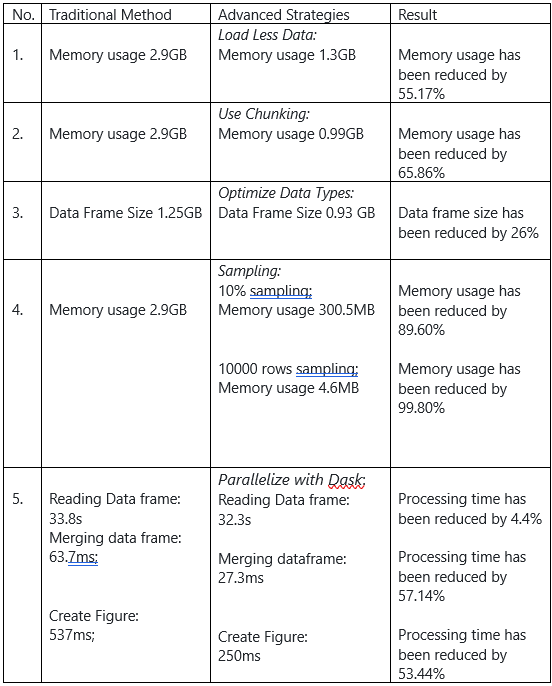




Based on the above comparative analysis, it indicates that the traditional method which is Pandas may have some limitations when dealing with large datasets in terms of memory usage and processing time. The advanced strategies give us the opportunity if Pandas still is an option for analysis where these strategies can reduce memory usage, enhance processing speed, and provide efficient ways to handle large datasets.

##Conclusion

In conclusion, the advanced strategies allow us to handle big data in Pandas as follows: -

a)	Load less data:: Instead of loading the entire dataset into memory, only loading the specific columns or rows that are required for the analysis will reduce the memory footprint and speed up operations. However, it may affect the decision due to not representing the entire dataset.

b)	Use chunking: When dealing with large datasets, chunks allow to processing of the data in smaller pieces to avoid memory issues. This is particularly useful when performing operations that don't require the entire dataset to be in memory simultaneously. However, certain operations might be more complex when working with chunks

c)	Optimized data types: Choosing the most memory-efficient data types for each column can significantly reduce memory usage and speed up computations due to reduced data size. Thus, it can improve overall performance.

d)	Sampling: Analyzing a sample of the data also can reduce memory usage and take less time for processing. Moreover, sampling can provide insights and help in understanding the overall characteristics of the dataset. However, certain rare events or patterns might be missed due to sampling might not represent the entire population accurately.

e)	Parallelize with Dask: Dask enables parallel and distributed computing, allowing computations to be split across multiple cores or even distributed across a cluster. This will help in handling larger-than-memory datasets by efficiently utilizing available computational resources.

In summary, depending on our goal, sampling strategies are the best for exploration purposes. In case we need to process all of our data, we can try iterating over data or optimizing the data types. If our dataset is still too large and takes more time to process, then we can go for Dask to parallelize Pandas. All of these strategies collectively aim to reduce memory usage, enhance processing speed, and provide efficient ways to handle large datasets without overwhelming system resources.
